REGUNTAS DE ANÁLISIS:

1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?
2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?
3. ¿Qué pares de grupos son significativamente diferentes?
4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?
5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?

# Actividad MANOVA

Ahora repite todo para el siguiente dataset de load_iris

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.datasets import load_iris, load_wine, load_diabetes # Necesaria para la actividad
from scipy.stats import f_oneway
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import statsmodels.api as sm
from statsmodels.formula.api import ols

In [79]:
# Celda 3: Cargar el dataset Iris (datos reales)
# El dataset Iris contiene mediciones de 3 especies de flores
iris = load_iris()

# Crear DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['Especie'] = iris.target_names[iris.target]

# Renombrar columnas para claridad
df.columns = ['Longitud_Sepalo', 'Ancho_Sepalo', 
              'Longitud_Petalo', 'Ancho_Petalo', 'Especie']

print(f"Forma del dataset: {df.shape}")
print(f"Especies: {df['Especie'].unique()}")
print(f"Observaciones por especie:")
print(df['Especie'].value_counts())
df.head(10)

Forma del dataset: (150, 5)
Especies: ['setosa' 'versicolor' 'virginica']
Observaciones por especie:
Especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,Longitud_Sepalo,Ancho_Sepalo,Longitud_Petalo,Ancho_Petalo,Especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [80]:
# Estadísticas descriptivas por especie
print("ESTADÍSTICAS DESCRIPTIVAS POR ESPECIE:\n")

estadisticas_iris = df.groupby('Especie').agg({
    'Longitud_Sepalo': ['mean', 'std', 'min', 'max'],
    'Ancho_Sepalo': ['mean', 'std', 'min', 'max'],
    'Longitud_Petalo': ['mean', 'std', 'min', 'max'],
    'Ancho_Petalo': ['mean', 'std', 'min', 'max']
}).round(2)

print(estadisticas_iris)

ESTADÍSTICAS DESCRIPTIVAS POR ESPECIE:

           Longitud_Sepalo                 Ancho_Sepalo                  \
                      mean   std  min  max         mean   std  min  max   
Especie                                                                   
setosa                5.01  0.35  4.3  5.8         3.43  0.38  2.3  4.4   
versicolor            5.94  0.52  4.9  7.0         2.77  0.31  2.0  3.4   
virginica             6.59  0.64  4.9  7.9         2.97  0.32  2.2  3.8   

           Longitud_Petalo                 Ancho_Petalo                  
                      mean   std  min  max         mean   std  min  max  
Especie                                                                  
setosa                1.46  0.17  1.0  1.9         0.25  0.11  0.1  0.6  
versicolor            4.26  0.47  3.0  5.1         1.33  0.20  1.0  1.8  
virginica             5.55  0.55  4.5  6.9         2.03  0.27  1.4  2.5  


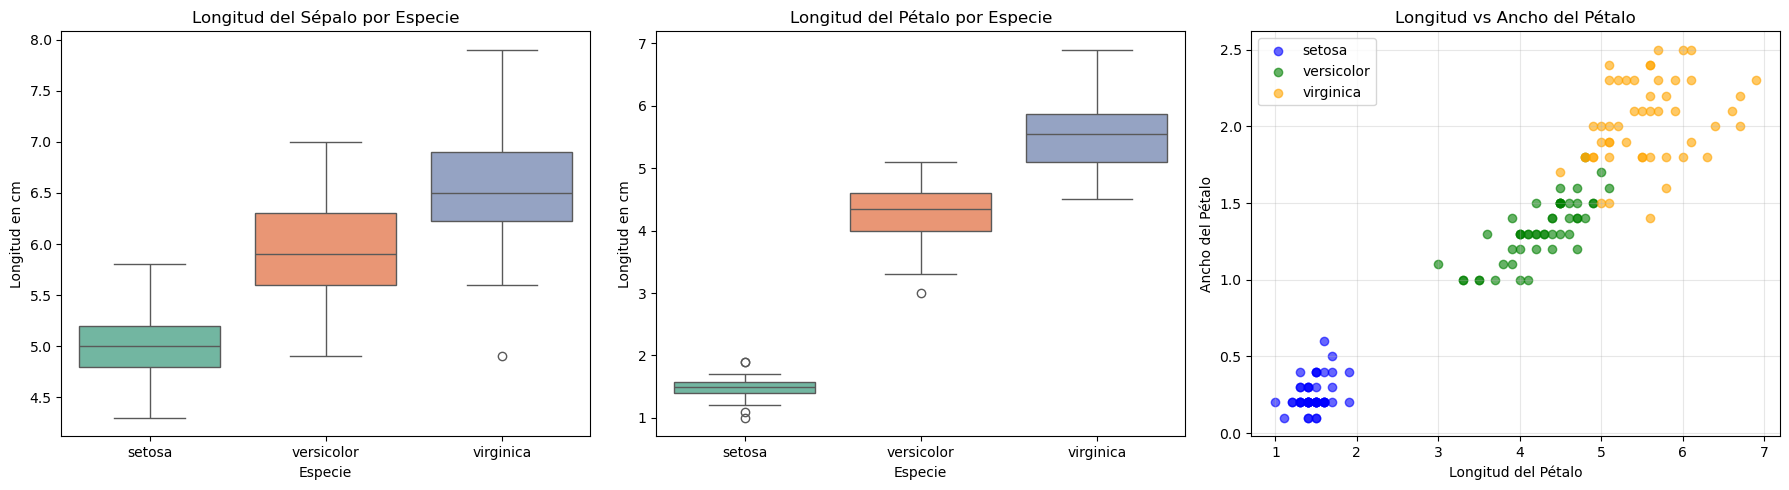

In [81]:
# Visualización
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Boxplot Longitud de Sépalo
sns.boxplot(x='Especie', y='Longitud_Sepalo', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Longitud del Sépalo por Especie')
axes[0].set_xlabel('Especie')
axes[0].set_ylabel('Longitud en cm')

# Boxplot Longitud de Pétalo
sns.boxplot(x='Especie', y='Longitud_Petalo', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Longitud del Pétalo por Especie')
axes[1].set_xlabel('Especie')
axes[1].set_ylabel('Longitud en cm')

# Scatter plot Longitud vs Ancho de Pétalo
colors = {'setosa': 'blue', 'versicolor': 'green', 'virginica': 'orange'}
for especie in df['Especie'].unique():
    subset = df[df['Especie'] == especie]
    axes[2].scatter(subset['Longitud_Petalo'], subset['Ancho_Petalo'], 
                    alpha=0.6, label=especie, color=colors[especie])
axes[2].set_xlabel('Longitud del Pétalo')
axes[2].set_ylabel('Ancho del Pétalo')
axes[2].set_title('Longitud vs Ancho del Pétalo')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

MATRIZ DE CORRELACIÓN

                 Longitud_Sepalo  Ancho_Sepalo  Longitud_Petalo  Ancho_Petalo
Longitud_Sepalo           1.0000       -0.1176           0.8718        0.8179
Ancho_Sepalo             -0.1176        1.0000          -0.4284       -0.3661
Longitud_Petalo           0.8718       -0.4284           1.0000        0.9629
Ancho_Petalo              0.8179       -0.3661           0.9629        1.0000


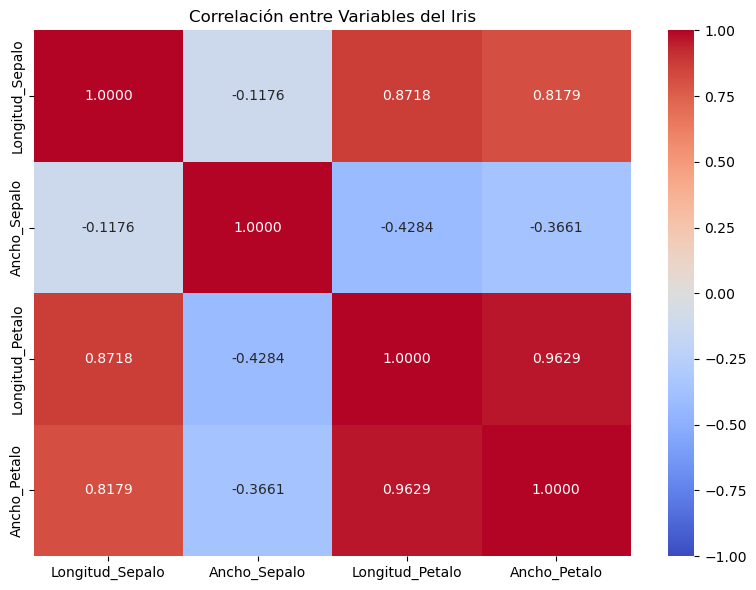

In [82]:
#Matriz de correlacion
print("MATRIZ DE CORRELACIÓN\n")
print(df[['Longitud_Sepalo', 'Ancho_Sepalo', 'Longitud_Petalo', 'Ancho_Petalo']].corr().round(4))

# Visualización
plt.figure(figsize=(8, 6))
sns.heatmap(df[['Longitud_Sepalo', 'Ancho_Sepalo', 'Longitud_Petalo', 'Ancho_Petalo']].corr(), 
            annot=True, cmap='coolwarm', center=0, 
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación entre Variables del Iris')
plt.tight_layout()
plt.show()

In [83]:
# MANOVA - Prueba principal
print("MANOVA - Dataset Iris\n")

# Ajustar MANOVA
manova = MANOVA.from_formula('Longitud_Sepalo + Ancho_Sepalo + Longitud_Petalo + Ancho_Petalo ~ Especie', data=df)
resultado = manova.mv_test()

print(resultado)

MANOVA - Dataset Iris

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0170 4.0000 144.0000 2086.7720 0.0000
         Pillai's trace  0.9830 4.0000 144.0000 2086.7720 0.0000
 Hotelling-Lawley trace 57.9659 4.0000 144.0000 2086.7720 0.0000
    Roy's greatest root 57.9659 4.0000 144.0000 2086.7720 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
        Especie          Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0234 8.0000 288.0000  199.1453 0.0000
         Pillai's trac

In [84]:
# Extraer resultados de los cuatro estadísticos
print("=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS (IRIS) ===\n")

# Extraer resultados del MANOVA
resultados_mv = manova.mv_test().results['Especie']['stat']

print("Estadísticos de prueba:")
print(resultados_mv.round(4))

=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS (IRIS) ===

Estadísticos de prueba:
                            Value Num DF     Den DF      F Value Pr > F
Wilks' lambda            0.023439      8      288.0   199.145344    0.0
Pillai's trace           1.191899    8.0      290.0    53.466489    0.0
Hotelling-Lawley trace   32.47732      8  203.40239   582.197018    0.0
Roy's greatest root     32.191929      4        145  1166.957433    0.0


In [85]:
# Interpretación de resultados
print("=== INTERPRETACIÓN DE RESULTADOS (IRIS) ===\n")

# Verificar significancia de cada estadístico
for estadistico in resultados_mv.index:
    if 'p-value' in resultados_mv.columns:
        p_valor = resultados_mv.loc[estadistico, 'Pr > F']
        valor = resultados_mv.loc[estadistico, 'Value']
        
        if p_valor < 0.05:
            print(f"✅ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → SIGNIFICATIVO")
        else:
            print(f"❌ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → NO SIGNIFICATIVO")

print("\n Conclusión:")
print("Todos los estadísticos son significativos (p < 0.05).")
print("Existe evidencia de que las especies de Iris difieren")
print("en el patrón conjunto de las cuatro variables morfológicas.")

=== INTERPRETACIÓN DE RESULTADOS (IRIS) ===


 Conclusión:
Todos los estadísticos son significativos (p < 0.05).
Existe evidencia de que las especies de Iris difieren
en el patrón conjunto de las cuatro variables morfológicas.


In [86]:
# ANOVA univariado post-hoc (con corrección de Bonferroni)
print("=== ANOVA UNIVARIADO POST-HOC (IRIS) ===\n")

# ANOVA para Longitud_Sepalo
print("ANOVA para Longitud_Sepalo:")
modelo_ls = ols('Longitud_Sepalo ~ Especie', data=df).fit()
anova_ls = sm.stats.anova_lm(modelo_ls, typ=2)
print(anova_ls.round(4))

# ANOVA para Ancho_Sepalo
print("\n ANOVA para Ancho_Sepalo:")
modelo_as = ols('Ancho_Sepalo ~ Especie', data=df).fit()
anova_as = sm.stats.anova_lm(modelo_as, typ=2)
print(anova_as.round(4))

# ANOVA para Longitud_Petalo
print("\n ANOVA para Longitud_Petalo:")
modelo_lp = ols('Longitud_Petalo ~ Especie', data=df).fit()
anova_lp = sm.stats.anova_lm(modelo_lp, typ=2)
print(anova_lp.round(4))

# ANOVA para Ancho_Petalo
print("\n ANOVA para Ancho_Petalo:")
modelo_ap = ols('Ancho_Petalo ~ Especie', data=df).fit()
anova_ap = sm.stats.anova_lm(modelo_ap, typ=2)
print(anova_ap.round(4))

# Corrección de Bonferroni
alpha = 0.05
alpha_bonferroni = alpha / 4  # 4 variables dependientes

print(f"\n Corrección de Bonferroni:")
print(f"   α original = {alpha}")
print(f"   α ajustado = {alpha_bonferroni}")

# Interpretación
p_ls = anova_ls.loc['Especie', 'PR(>F)']
p_as = anova_as.loc['Especie', 'PR(>F)']
p_lp = anova_lp.loc['Especie', 'PR(>F)']
p_ap = anova_ap.loc['Especie', 'PR(>F)']

print(f"\n   Longitud_Sepalo: p = {p_ls:.4f} → {'Significativo' if p_ls < alpha_bonferroni else 'No significativo'}")
print(f"   Ancho_Sepalo:    p = {p_as:.4f} → {'Significativo' if p_as < alpha_bonferroni else 'No significativo'}")
print(f"   Longitud_Petalo: p = {p_lp:.4f} → {'Significativo' if p_lp < alpha_bonferroni else 'No significativo'}")
print(f"   Ancho_Petalo:    p = {p_ap:.4f} → {'Significativo' if p_ap < alpha_bonferroni else 'No significativo'}")

=== ANOVA UNIVARIADO POST-HOC (IRIS) ===

ANOVA para Longitud_Sepalo:
           sum_sq     df         F  PR(>F)
Especie   63.2121    2.0  119.2645     0.0
Residual  38.9562  147.0       NaN     NaN

 ANOVA para Ancho_Sepalo:
           sum_sq     df      F  PR(>F)
Especie   11.3449    2.0  49.16     0.0
Residual  16.9620  147.0    NaN     NaN

 ANOVA para Longitud_Petalo:
            sum_sq     df          F  PR(>F)
Especie   437.1028    2.0  1180.1612     0.0
Residual   27.2226  147.0        NaN     NaN

 ANOVA para Ancho_Petalo:
           sum_sq     df         F  PR(>F)
Especie   80.4133    2.0  960.0071     0.0
Residual   6.1566  147.0       NaN     NaN

 Corrección de Bonferroni:
   α original = 0.05
   α ajustado = 0.0125

   Longitud_Sepalo: p = 0.0000 → Significativo
   Ancho_Sepalo:    p = 0.0000 → Significativo
   Longitud_Petalo: p = 0.0000 → Significativo
   Ancho_Petalo:    p = 0.0000 → Significativo


In [87]:
# Comparaciones múltiples post-hoc (Tukey HSD)
print("COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) - IRIS\n")

variables = ['Longitud_Sepalo', 'Ancho_Sepalo', 'Longitud_Petalo', 'Ancho_Petalo']

for var in variables:
    print(f"Tukey HSD para {var}:")
    tukey = pairwise_tukeyhsd(df[var], df['Especie'], alpha=0.05)
    print(tukey)
    print()

COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) - IRIS

Tukey HSD para Longitud_Sepalo:
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     0.93   0.0 0.6862 1.1738   True
    setosa  virginica    1.582   0.0 1.3382 1.8258   True
versicolor  virginica    0.652   0.0 0.4082 0.8958   True
---------------------------------------------------------

Tukey HSD para Ancho_Sepalo:
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1     group2   meandiff p-adj   lower   upper  reject
------------------------------------------------------------
    setosa versicolor   -0.658    0.0 -0.8189 -0.4971   True
    setosa  virginica   -0.454    0.0 -0.6149 -0.2931   True
versicolor  virginica    0.204 0.0088  0.0431  0.3649   True
------------------------------------------------------------

Tukey HSD para Longitud_Petalo:
   Multiple Compari

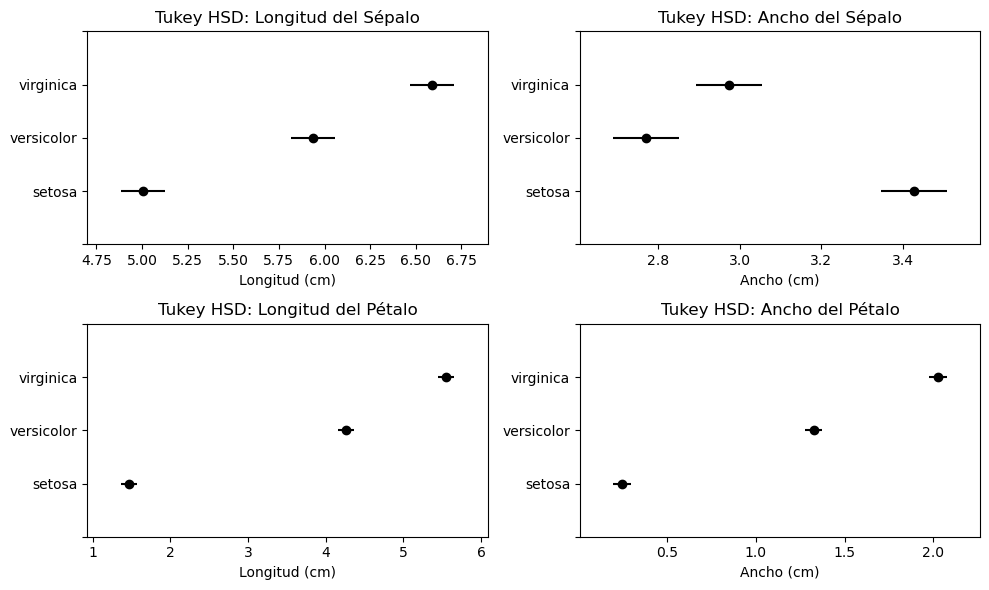

In [88]:
# Visualización de Tukey HSD (IRIS)
fig, axes = plt.subplots(2, 2, figsize=(28, 10))

# Tukey Longitud_Sepalo
tukey_ls = pairwise_tukeyhsd(df['Longitud_Sepalo'], df['Especie'], alpha=0.05)
tukey_ls.plot_simultaneous(ax=axes[0, 0])
axes[0, 0].set_title('Tukey HSD: Longitud del Sépalo')
axes[0, 0].set_xlabel('Longitud (cm)')

# Tukey Ancho_Sepalo
tukey_as = pairwise_tukeyhsd(df['Ancho_Sepalo'], df['Especie'], alpha=0.05)
tukey_as.plot_simultaneous(ax=axes[0, 1])
axes[0, 1].set_title('Tukey HSD: Ancho del Sépalo')
axes[0, 1].set_xlabel('Ancho (cm)')

# Tukey Longitud_Petalo
tukey_lp = pairwise_tukeyhsd(df['Longitud_Petalo'], df['Especie'], alpha=0.05)
tukey_lp.plot_simultaneous(ax=axes[1, 0])
axes[1, 0].set_title('Tukey HSD: Longitud del Pétalo')
axes[1, 0].set_xlabel('Longitud (cm)')

# Tukey Ancho_Petalo
tukey_ap = pairwise_tukeyhsd(df['Ancho_Petalo'], df['Especie'], alpha=0.05)
tukey_ap.plot_simultaneous(ax=axes[1, 1])
axes[1, 1].set_title('Tukey HSD: Ancho del Pétalo')
axes[1, 1].set_xlabel('Ancho (cm)')

plt.tight_layout()
plt.show()

In [89]:
# Verificación de supuestos - Normalidad multivariada
print("=== VERIFICACIÓN DE SUPUESTOS (IRIS) ===\n")
print("--- Normalidad Multivariada ---\n")

def mardia_test(data, alpha=0.05):
    """
        Implementación simplificada del test de Mardia
    """
    n, p = data.shape
    mean = np.mean(data, axis=0)
    centered = data - mean
    S = np.cov(data, rowvar=False)
    S_inv = np.linalg.inv(S)
    
    # Asimetría multivariada
    b1p = 0
    for i in range(n):
        for j in range(n):
            b1p += (centered[i] @ S_inv @ centered[j])**3
    b1p = b1p / (n**2)
    
    # Curtosis multivariada
    b2p = 0
    for i in range(n):
        b2p += (centered[i] @ S_inv @ centered[i])**2
    b2p = b2p / n
        
    # Estadísticos de prueba
    skewness_stat = n * b1p / 6
    kurtosis_stat = (b2p - p*(p+2)) / np.sqrt(8*p*(p+2)/n)
    
    # p-valores
    p_skewness = 1 - stats.chi2.cdf(skewness_stat, p*(p+1)*(p+2)/6)
    p_kurtosis = 2 * (1 - stats.norm.cdf(abs(kurtosis_stat)))
    
    return {
        'Skewness statistic': skewness_stat,
        'Skewness p-value': p_skewness,
        'Kurtosis statistic': kurtosis_stat,
        'Kurtosis p-value': p_kurtosis
    }

variables = ['Longitud_Sepalo', 'Ancho_Sepalo', 'Longitud_Petalo', 'Ancho_Petalo']

# Aplicar test por grupo
for especie in df['Especie'].unique():
    subset = df[df['Especie'] == especie][variables].values
    print(f"Especie {especie}:")
    resultado = mardia_test(subset)
    for key, value in resultado.items():
        print(f"  {key}: {value:.4f}")
    
    if resultado['Skewness p-value'] > 0.05 and resultado['Kurtosis p-value'] > 0.05:
        print("  ✅ Normalidad multivariada aceptable")
    else:
        print("  ⚠️ Posible violación de normalidad multivariada")
    print()

=== VERIFICACIÓN DE SUPUESTOS (IRIS) ===

--- Normalidad Multivariada ---

Especie setosa:
  Skewness statistic: 24.1551
  Skewness p-value: 0.2357
  Kurtosis statistic: 0.7587
  Kurtosis p-value: 0.4480
  ✅ Normalidad multivariada aceptable

Especie versicolor:
  Skewness statistic: 23.7039
  Skewness p-value: 0.2556
  Kurtosis statistic: -1.0342
  Kurtosis p-value: 0.3010
  ✅ Normalidad multivariada aceptable

Especie virginica:
  Skewness statistic: 24.7257
  Skewness p-value: 0.2121
  Kurtosis statistic: -0.3384
  Kurtosis p-value: 0.7350
  ✅ Normalidad multivariada aceptable



In [90]:
# Verificación de supuestos - Homogeneidad de covarianzas (Box's M)
print(" Homogeneidad de Matrices de Covarianza (Box's M) - IRIS \n")

def box_m_test(data, groups):
    """
    Implementación del test M de Box
    """
    group_names = groups.unique()
    k = len(group_names)
    p = data.shape[1]
    
    # Tamaños de muestra
    ns = [len(data[groups == g]) for g in group_names]
    n_total = sum(ns)
    
    # Matrices de covarianza por grupo
    covs = []
    for g in group_names:
        subset = data[groups == g]
        covs.append(np.cov(subset, rowvar=False))
    
    # Covarianza pooled
    pooled_cov = sum([(n-1) * cov for n, cov in zip(ns, covs)]) / (n_total - k)
    
    # Estadístico M
    M = (n_total - k) * np.log(np.linalg.det(pooled_cov))
    for n, cov in zip(ns, covs):
        M -= (n - 1) * np.log(np.linalg.det(cov))
    
    # Factor de corrección
    c = (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    c *= sum([1/(n-1) for n in ns]) - 1/(n_total - k)
    
    # Estadístico de prueba
    chi2_stat = M * (1 - c)
    
    # Grados de libertad
    df = p * (p + 1) * (k - 1) / 2
    
    # p-valor
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)
    
    return {
        'M statistic': M,
        'Chi-square': chi2_stat,
        'df': df,
        'p-value': p_value
    }

# Aplicar Box's M
resultado_box = box_m_test(df[['Longitud_Sepalo', 'Ancho_Sepalo', 'Longitud_Petalo', 'Ancho_Petalo']], df['Especie'])
print("Resultados del test M de Box:")
for key, value in resultado_box.items():
    print(f"  {key}: {value:.4f}")

if resultado_box['p-value'] > 0.05:
    print("\n✅ No se rechaza H₀: Las matrices de covarianza son homogéneas")
else:
    print("\n⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas")
    print("   → Considerar usar Pillai's Trace (más robusto)")

 Homogeneidad de Matrices de Covarianza (Box's M) - IRIS 

Resultados del test M de Box:
  M statistic: 146.6632
  Chi-square: 140.9430
  df: 20.0000
  p-value: 0.0000

⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas
   → Considerar usar Pillai's Trace (más robusto)
